# Classificação de recomendação em reviews da Steam com Jev

Neste notebook usaremos o **Jev**, modelo System One da TypeSafe AI, para responder à pergunta:

> **Com base apenas no texto da review, o usuário recomendaria ou não o jogo?**

O corpus será `_DadosLimpos/steam_reviews.pkl.gz`. O texto da coluna `review` será enviado ao modelo e a resposta será comparada com o rótulo real `voted_up` fornecido pela Steam:

- `voted_up = True` → `recomenda`;
- `voted_up = False` → `nao_recomenda`.

Ao contrário do notebook local com TF-IDF, aqui não há treinamento sobre o corpus. O Jev será avaliado em regime **zero-shot**, por meio de chamadas a uma API externa.

## 1. Abordagens comparadas

**TF-IDF + Regressão Logística**

`reviews rotuladas → treinamento local → classificador → previsão`

**Jev**

`review → state + proposição tipada → API Jev → decisão estruturada`

Usaremos a primitiva `Noul`, que avalia uma proposição binária e retorna um valor entre 0 e 1. Não usaremos uma escala de estrelas porque os dados coletados da Steam não possuem nota real de 1 a 5 para comparação.

## 2. Instalação e bibliotecas

Cada classificação realizada pelo Jev é uma chamada externa. Verifique previamente os custos, limites de uso e política de dados da API.

In [10]:
%pip install typesafe-sdk pandas matplotlib scikit-learn


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [11]:
import os
import time
from getpass import getpass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    f1_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from typesafe_sdk import Noul, TypeSafeClient

RANDOM_STATE = 42

## 3. Chave da API

A chave é solicitada com `getpass`, portanto não aparece na saída nem fica gravada no notebook. Se `TYPESAFE_API_KEY` já estiver definida no ambiente, ela será reutilizada.

> Nunca escreva chaves diretamente em células, comentários, arquivos versionados ou saídas do notebook. Se uma chave for exposta, revogue-a e gere outra.

In [12]:
if not os.environ.get('TYPESAFE_API_KEY'):
    chave = getpass('Digite sua TYPESAFE_API_KEY: ').strip()
    if not chave:
        raise ValueError('A chave da API não pode ser vazia.')
    os.environ['TYPESAFE_API_KEY'] = chave

print('Chave disponível apenas no ambiente da sessão atual.')

Chave disponível apenas no ambiente da sessão atual.


## 4. Carregando as reviews da Steam

O código localiza a raiz do repositório mesmo quando o notebook é executado dentro de `5_Classificacao`. O pickle é carregado localmente; apenas os textos selecionados para a amostra serão enviados à API.

In [13]:
def localizar_raiz(inicio=Path.cwd()):
    inicio = inicio.resolve()
    for pasta in (inicio, *inicio.parents):
        arquivo = pasta / '_DadosLimpos' / 'steam_reviews.pkl.gz'
        if arquivo.is_file():
            return pasta
    raise FileNotFoundError(
        'Não foi encontrado _DadosLimpos/steam_reviews.pkl.gz. '
        'Execute o notebook dentro do repositório PLN_SteamRecommend.'
    )

RAIZ = localizar_raiz()
CAMINHO_DADOS = RAIZ / '_DadosLimpos' / 'steam_reviews.pkl.gz'

reviews_completas = pd.read_pickle(CAMINHO_DADOS)
colunas_necessarias = [
    'appid', 'game_name', 'review', 'voted_up', 'review_type', 'review_idioma'
]
colunas_ausentes = set(colunas_necessarias) - set(reviews_completas.columns)
if colunas_ausentes:
    raise ValueError(f'Colunas ausentes no arquivo: {sorted(colunas_ausentes)}')

df = reviews_completas[colunas_necessarias].copy()
del reviews_completas

print('Arquivo:', CAMINHO_DADOS)
print('Dimensões:', df.shape)
df.head()

Arquivo: /Users/vinicius/Documents/GitHub/PLN_SteamRecommend/_DadosLimpos/steam_reviews.pkl.gz
Dimensões: (395256, 6)


,appid,game_name,review,voted_up,review_type,review_idioma
0,10,Counter-Strike,"Good game, most perfect counter strike ever ex...",True,positive,en
2,10,Counter-Strike,This game is good for anyone who wants a smoot...,True,positive,en
8,10,Counter-Strike,Very good game. I like the older graphics and ...,True,positive,en
9,10,Counter-Strike,"This? Is a masterpiece. It has a lot of mods, ...",True,positive,en
10,10,Counter-Strike,despite playing this regularly at the ripe age...,False,negative,en


## 5. Inspeção e prevenção de vazamento

A coluna `review_type` é útil para auditoria, mas não será enviada ao Jev. Ela praticamente replica o rótulo e entregaria a resposta sem necessidade de analisar a linguagem da review.

O único conteúdo enviado como `state` será a coluna `review`.

In [14]:
print('Valores ausentes:')
print(df.isna().sum())

print('\nIdiomas:')
print(df['review_idioma'].value_counts(dropna=False))

print('\nRótulos reais:')
print(df['voted_up'].value_counts(dropna=False))

tipo_indica_positivo = df['review_type'].eq('positive')
inconsistencias = tipo_indica_positivo.ne(df['voted_up'])
print('\nDivergências entre review_type e voted_up:', int(inconsistencias.sum()))

Valores ausentes:
appid            0
game_name        0
review           0
voted_up         0
review_type      0
review_idioma    0
dtype: int64

Idiomas:
review_idioma
en    395256
Name: count, dtype: int64

Rótulos reais:
voted_up
False    206472
True     188784
Name: count, dtype: int64

Divergências entre review_type e voted_up: 15


## 6. Preparação mínima

Como o texto será interpretado diretamente pelo Jev, não aplicaremos TF-IDF, stemming, lematização nem remoção de stopwords. Apenas normalizaremos espaços e trataremos duplicatas.

In [15]:
df = df.dropna(subset=['review', 'voted_up']).copy()
df['review'] = (
    df['review']
    .astype(str)
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)
df = df[df['review'].str.len() > 0].copy()

rotulos_por_texto = df.groupby('review', sort=False)['voted_up'].transform('nunique')
df = df.loc[rotulos_por_texto.eq(1)].drop_duplicates(subset='review').copy()
df['recomendacao'] = df['voted_up'].map(
    {False: 'nao_recomenda', True: 'recomenda'}
)

print('Registros disponíveis após preparação:', len(df))
print(df['recomendacao'].value_counts())

Registros disponíveis após preparação: 392300
recomendacao
nao_recomenda    205521
recomenda        186779
Name: count, dtype: int64


## 7. Amostra balanceada para a API

Cada review processada representa uma chamada à API. Com o padrão de 10 exemplos por classe, a avaliação principal usa 20 chamadas. A célula de inspeção anterior à avaliação faz mais uma chamada.

A amostra é balanceada entre usuários que recomendaram e não recomendaram o jogo. Aumente o valor somente depois de considerar custo, privacidade e limites da API.

In [16]:
AMOSTRA_POR_CLASSE = 10

amostra_jev = (
    df.groupby('recomendacao', group_keys=False)
    .sample(n=AMOSTRA_POR_CLASSE, random_state=RANDOM_STATE)
    .sample(frac=1, random_state=RANDOM_STATE)
    .reset_index(drop=True)
)

print('Tamanho da amostra:', len(amostra_jev))
print(amostra_jev['recomendacao'].value_counts())
amostra_jev[['game_name', 'review', 'recomendacao']].head(10)

Tamanho da amostra: 20
recomendacao
nao_recomenda    10
recomenda        10
Name: count, dtype: int64


,game_name,review,recomendacao
0,Outlast 2,"Great vibes, interesting lore, weaker jumpscar...",nao_recomenda
1,The Witcher 3: Wild Hunt - Complete Edition,They just upgraded my base game to the complet...,recomenda
2,Epic Battle Fantasy 4,This is a flash game cornerstone. For what is ...,recomenda
3,Buddy and Lucky Solitaire,"Honestly a rather bland, graphical bug-riddled...",nao_recomenda
4,Glare1more,"It's like ""Her Story"" just clunkier and an ove...",nao_recomenda
5,Gunmetal Arcadia Zero,[h1]Gameplay: 3/10[/h1] [h1]Graphics & Sound: ...,nao_recomenda
6,Sloppy Fields,Right now as of playing only the last 2 blank ...,recomenda
7,Leaving DNA,In short; a high quality production with a lon...,nao_recomenda
8,Awesome Pea,awesome pea is a game that blurs the line betw...,recomenda
9,Blameless,"Good little game, decent puzzles, nothing extr...",recomenda


## 8. Definindo a proposição para o Jev

`Noul` retornará um sinal entre 0 e 1 para a proposição de que o autor recomendaria o jogo. A instrução explicita que a decisão deve usar somente o texto e que críticas isoladas não significam necessariamente uma recomendação negativa.

In [17]:
PERGUNTAS_JEV = {
    'recomendaria': Noul(
        instructions=(
            'Based only on the Steam review text, would the author recommend '
            'the video game? Consider the overall conclusion of the review, '
            'including negation, mixed opinions and explicit recommendation '
            'statements. Evaluate whether the author would select the Steam '
            'Recommended option.'
        )
    )
}

PERGUNTAS_JEV

{'recomendaria': Noul(type='noul', instructions='Based only on the Steam review text, would the author recommend the video game? Consider the overall conclusion of the review, including negation, mixed opinions and explicit recommendation statements. Evaluate whether the author would select the Steam Recommended option.', criteria=None)}

## 9. Teste de uma chamada

Antes de processar a amostra completa, executaremos uma chamada para verificar a chave, a conexão e a estrutura da resposta. Esse texto será processado novamente na avaliação principal.

In [32]:
texto_exemplo = amostra_jev.loc[10, 'review']

print('Texto:')
print(texto_exemplo)
print('\nRótulo real:', amostra_jev.loc[10, 'recomendacao'])

with TypeSafeClient() as client:
    resposta_exemplo = client.system_one(
        state=texto_exemplo,
        questions=PERGUNTAS_JEV,
    )

Texto:
There comes a time in every generation of man that great art is created and distributed to the masses. Buy this game right now, try not to masturbate so you can keep your hands on the controls, and get 3 friends to hump you into a tower!

Rótulo real: recomenda


In [33]:
prob_exemplo = float(resposta_exemplo.answers['recomendaria'].noul)
print('Sinal de recomendação retornado pelo Jev:', round(prob_exemplo, 4))
print(
    'Classe com limiar 0.5:',
    'recomenda' if prob_exemplo >= 0.5 else 'nao_recomenda',
)

Sinal de recomendação retornado pelo Jev: 0.68
Classe com limiar 0.5: recomenda


## 10. Função de classificação

Usaremos inicialmente o limiar `0.5`. A confiança operacional abaixo mede apenas a distância do valor retornado até esse limiar:

`confianca = 2 × |probabilidade − 0.5|`

Essa medida varia de 0 a 1, mas não deve ser interpretada como probabilidade de acerto nem como calibração estatística.

In [34]:
LIMIAR_RECOMENDACAO = 0.5

def classificar_com_jev(texto, client):
    resposta = client.system_one(
        state=texto,
        questions=PERGUNTAS_JEV,
    )
    prob_recomendacao = float(
        resposta.answers['recomendaria'].noul
    )
    recomendacao_prevista = (
        'recomenda'
        if prob_recomendacao >= LIMIAR_RECOMENDACAO
        else 'nao_recomenda'
    )
    confianca_limiar = 2 * abs(prob_recomendacao - 0.5)

    return {
        'jev_prob_recomendacao': prob_recomendacao,
        'jev_recomendacao': recomendacao_prevista,
        'jev_confianca_limiar': confianca_limiar,
    }

## 11. Aplicando o Jev à amostra

A execução é sequencial para facilitar o acompanhamento. Falhas ficam registradas em `erro_jev` e não interrompem os demais casos. O intervalo pode ser ajustado de acordo com os limites da API.

In [35]:
INTERVALO_ENTRE_CHAMADAS = 0.2
resultados_api = []

with TypeSafeClient() as client:
    for indice, linha in amostra_jev.iterrows():
        try:
            resultado = classificar_com_jev(linha['review'], client)
            resultado['erro_jev'] = None
        except Exception as erro:
            resultado = {
                'jev_prob_recomendacao': None,
                'jev_recomendacao': None,
                'jev_confianca_limiar': None,
                'erro_jev': str(erro),
            }

        resultados_api.append(resultado)
        print(f'{indice + 1}/{len(amostra_jev)} concluído', end='\r')
        time.sleep(INTERVALO_ENTRE_CHAMADAS)

print('\nProcessamento concluído.')

20/20 concluído
Processamento concluído.


## 12. Organizando os resultados

Juntaremos o rótulo real da Steam e a decisão do Jev. Somente chamadas concluídas com sucesso entram nas métricas.

In [36]:
resultados_jev = pd.concat(
    [amostra_jev.reset_index(drop=True), pd.DataFrame(resultados_api)],
    axis=1,
)
resultados_validos = resultados_jev[resultados_jev['erro_jev'].isna()].copy()

print('Casos avaliados com sucesso:', len(resultados_validos), '/', len(resultados_jev))
if resultados_validos.empty:
    raise RuntimeError('Nenhuma chamada ao Jev foi concluída com sucesso.')

resultados_validos[[
    'game_name', 'review', 'recomendacao',
    'jev_prob_recomendacao', 'jev_recomendacao',
]].head()

Casos avaliados com sucesso: 20 / 20


,game_name,review,recomendacao,jev_prob_recomendacao,jev_recomendacao
0,Outlast 2,"Great vibes, interesting lore, weaker jumpscar...",nao_recomenda,0.45,nao_recomenda
1,The Witcher 3: Wild Hunt - Complete Edition,They just upgraded my base game to the complet...,recomenda,0.73,recomenda
2,Epic Battle Fantasy 4,This is a flash game cornerstone. For what is ...,recomenda,0.55,recomenda
3,Buddy and Lucky Solitaire,"Honestly a rather bland, graphical bug-riddled...",nao_recomenda,0.04,nao_recomenda
4,Glare1more,"It's like ""Her Story"" just clunkier and an ove...",nao_recomenda,0.10,nao_recomenda


In [37]:
falhas = resultados_jev[resultados_jev['erro_jev'].notna()]
print('Falhas:', len(falhas))
falhas[['review', 'erro_jev']].head()

Falhas: 0


,review,erro_jev


## 13. Avaliação da classificação

Calcularemos acurácia, acurácia balanceada, F1 por classe, matriz de confusão e ROC-AUC. Com apenas 20 exemplos, os números são demonstrativos e possuem grande incerteza; uma comparação rigorosa exige uma amostra maior e previamente fixada.

In [38]:
ordem_classes = ['nao_recomenda', 'recomenda']
y_true = resultados_validos['recomendacao']
y_pred = resultados_validos['jev_recomendacao']
prob_recomenda = resultados_validos['jev_prob_recomendacao'].astype(float)

print(f'Acurácia: {accuracy_score(y_true, y_pred):.3f}')
print(f'Acurácia balanceada: {balanced_accuracy_score(y_true, y_pred):.3f}')
print(f'F1 macro: {f1_score(y_true, y_pred, average="macro"):.3f}')
print('\nRelatório por classe:\n')
print(
    classification_report(
        y_true, y_pred, labels=ordem_classes, digits=3, zero_division=0
    )
)

Acurácia: 0.850
Acurácia balanceada: 0.850
F1 macro: 0.850

Relatório por classe:

               precision    recall  f1-score   support

nao_recomenda      0.889     0.800     0.842        10
    recomenda      0.818     0.900     0.857        10

     accuracy                          0.850        20
    macro avg      0.854     0.850     0.850        20
 weighted avg      0.854     0.850     0.850        20



ROC-AUC: 0.895


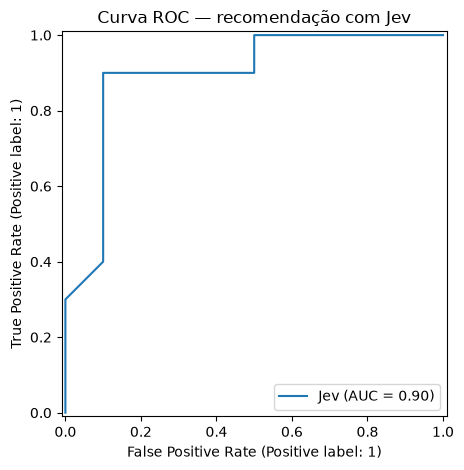

In [39]:
if y_true.nunique() == 2:
    y_true_auc = y_true.eq('recomenda')
    auc = roc_auc_score(y_true_auc, prob_recomenda)
    print(f'ROC-AUC: {auc:.3f}')

    RocCurveDisplay.from_predictions(
        y_true_auc,
        prob_recomenda,
        name='Jev',
    )
    plt.title('Curva ROC — recomendação com Jev')
    plt.tight_layout()
    plt.show()
else:
    print('ROC-AUC não calculada: as chamadas válidas não contêm as duas classes.')

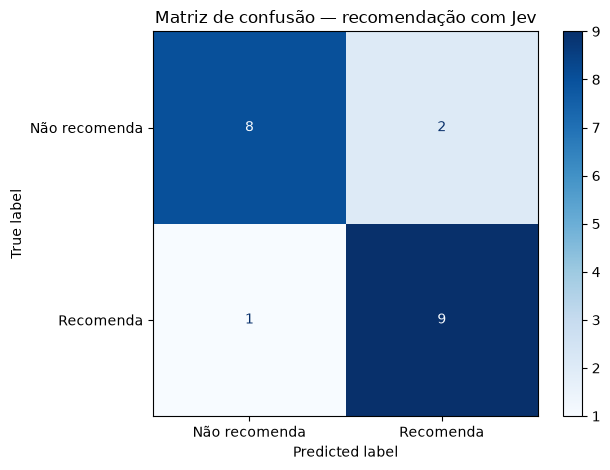

In [40]:
ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=ordem_classes,
    display_labels=['Não recomenda', 'Recomenda'],
    cmap='Blues',
    values_format='d',
)
plt.title('Matriz de confusão — recomendação com Jev')
plt.tight_layout()
plt.show()

## 14. Confiança operacional e erros

Casos próximos de 0.5 são mais sensíveis ao limiar. Casos incorretos e distantes do limiar ajudam a encontrar ironia, reviews mistas, instruções inadequadas ou divergências entre o texto e a escolha registrada pelo usuário.

In [41]:
resultados_validos[[
    'review', 'recomendacao', 'jev_recomendacao',
    'jev_prob_recomendacao', 'jev_confianca_limiar',
]].sort_values('jev_confianca_limiar').head(10)

,review,recomendacao,jev_recomendacao,jev_prob_recomendacao,jev_confianca_limiar
14,"Buy SoI for ""Japan Map"" Buy ROTK13 for ""Office...",nao_recomenda,recomenda,0.51,0.02
0,"Great vibes, interesting lore, weaker jumpscar...",nao_recomenda,nao_recomenda,0.45,0.10
2,This is a flash game cornerstone. For what is ...,recomenda,recomenda,0.55,0.10
8,awesome pea is a game that blurs the line betw...,recomenda,recomenda,0.62,0.24
16,It was neat to find out how much i dont know a...,nao_recomenda,nao_recomenda,0.35,0.30
18,"Decent for a dollar. I'd say it's a cool game,...",recomenda,recomenda,0.65,0.30
17,Entertaining hour long game for $0.84. Neat in...,recomenda,recomenda,0.67,0.34
10,There comes a time in every generation of man ...,recomenda,recomenda,0.68,0.36
1,They just upgraded my base game to the complet...,recomenda,recomenda,0.73,0.46
7,In short; a high quality production with a lon...,nao_recomenda,recomenda,0.73,0.46


In [42]:
erros = resultados_validos[
    resultados_validos['recomendacao'] != resultados_validos['jev_recomendacao']
].sort_values('jev_confianca_limiar', ascending=False)

print('Quantidade de erros:', len(erros))
erros[[
    'game_name', 'review', 'recomendacao', 'jev_recomendacao',
    'jev_prob_recomendacao', 'jev_confianca_limiar',
]]

Quantidade de erros: 3


,game_name,review,recomendacao,jev_recomendacao,jev_prob_recomendacao,jev_confianca_limiar
13,Paper2Galgame,Ruka-chan read the fine print and let me know ...,recomenda,nao_recomenda,0.14,0.72
7,Leaving DNA,In short; a high quality production with a lon...,nao_recomenda,recomenda,0.73,0.46
14,NOBUNAGA'S AMBITION: Sphere of Influence - Asc...,"Buy SoI for ""Japan Map"" Buy ROTK13 for ""Office...",nao_recomenda,recomenda,0.51,0.02


## 15. Testando reviews criadas manualmente

Os textos estão em inglês porque o corpus preparado para o projeto contém somente reviews identificadas nesse idioma. Cada texto abaixo gera uma chamada adicional à API.

In [43]:
textos_teste = [
    'Amazing game, fun with friends and absolutely worth the price.',
    'The game crashes constantly and I cannot recommend it.',
    'It has many problems, but I still recommend buying it on sale.',
    'Beautiful graphics, terrible controls and boring gameplay.',
    'I played for hours and I am still not sure if it was worth it.',
]

resultados_teste = []
with TypeSafeClient() as client:
    for texto in textos_teste:
        resultado = classificar_com_jev(texto, client)
        resultado['review'] = texto
        resultados_teste.append(resultado)

pd.DataFrame(resultados_teste)[[
    'review', 'jev_prob_recomendacao',
    'jev_recomendacao', 'jev_confianca_limiar',
]]

,review,jev_prob_recomendacao,jev_recomendacao,jev_confianca_limiar
0,"Amazing game, fun with friends and absolutely ...",0.96,recomenda,0.92
1,The game crashes constantly and I cannot recom...,0.03,nao_recomenda,0.94
2,"It has many problems, but I still recommend bu...",0.72,recomenda,0.44
3,"Beautiful graphics, terrible controls and bori...",0.12,nao_recomenda,0.76
4,I played for hours and I am still not sure if ...,0.32,nao_recomenda,0.36


## 16. TF-IDF + Regressão Logística versus Jev

| Aspecto | TF-IDF + Regressão Logística | Jev |
|---|---|---|
| Treinamento no corpus Steam | necessário | não utilizado |
| Execução | local | API externa |
| Nova tarefa | requer novo alvo/treinamento | requer nova proposição |
| Interpretabilidade | coeficientes dos termos | valor estruturado do `Noul` |
| Custo por inferência | computação local | chamada externa |
| Reprodutibilidade | versão local controlável | depende também da versão remota |
| Privacidade | texto permanece local | texto selecionado é enviado ao provedor |

Uma comparação justa deve usar exatamente o mesmo conjunto de teste para as duas abordagens e registrar as versões dos modelos e dependências.

## 17. Salvando os resultados

Salvar as respostas evita repetir chamadas pagas durante análises posteriores. O arquivo não contém a chave da API.

In [44]:
SALVAR_RESULTADOS = True
CAMINHO_RESULTADOS = RAIZ / '5_Classificacao' / 'resultados_jev_steam.csv'

if SALVAR_RESULTADOS:
    resultados_jev.to_csv(CAMINHO_RESULTADOS, index=False)
    print('Resultados salvos em:', CAMINHO_RESULTADOS)
else:
    print('Resultados não salvos.')

Resultados salvos em: /Users/vinicius/Documents/GitHub/PLN_SteamRecommend/5_Classificacao/resultados_jev_steam.csv


## 18. Limitações e próximos passos

- Uma amostra de 20 reviews serve como demonstração, não como estimativa estável de desempenho.
- O valor do `Noul` não deve ser chamado automaticamente de probabilidade calibrada.
- A formulação da proposição influencia a tarefa operacional.
- O rótulo `voted_up` representa a escolha registrada na Steam, que pode não estar explícita no texto.
- Reviews enviadas à API deixam o ambiente local; avalie requisitos de privacidade e governança.
- Mudanças no modelo remoto podem alterar resultados futuros.

Próximos passos sugeridos:

1. aumentar e fixar a amostra de avaliação;
2. usar a mesma amostra no modelo TF-IDF local;
3. repetir o teste com diferentes formulações da proposição;
4. estudar o limiar de decisão em um conjunto de validação separado;
5. analisar erros por jogo, extensão da review e linguagem mista;
6. registrar a versão do modelo remoto quando a API disponibilizar essa informação.

## Referências

- TypeSafe AI — Introduction: https://docs.typesafe.ai/introduction
- TypeSafe AI — Quick start: https://docs.typesafe.ai/introduction/quickstart
- TypeSafe AI — Noul: https://docs.typesafe.ai/primitives/noul
- Scikit-learn — Classification metrics: https://scikit-learn.org/stable/api/sklearn.metrics.html
- Steamworks — User Reviews: https://partner.steamgames.com/doc/store/reviews